# RNA-MLP com dados sintéticos

Demonstração de um pipeline de aprendizado de máquina para dados tabulares: geração, limpeza, treino, comparação de modelos e avaliação.

**Todos os registros são fictícios**, criados pelo arquivo `gerar_dados.py`. Nenhuma base externa é lida. UFs, municípios e identificadores são de demonstração.

Execute a partir da pasta do projeto, usando o ambiente descrito no README. **Executar tudo** recria os dados, os modelos, os gráficos e o PDF.

## Experimento

São gerados 500 municípios fictícios, com tamanhos de grupo variáveis e cinco regiões. As proporções das classes são arbitrárias. O gerador inclui ausências categóricas, identificadores ausentes, acentos e contagens com separador de milhar.

Treino, validação e teste usam municípios distintos (60/20/20 dos grupos). Encoder e MinMaxScaler aprendem somente no treino. Três configurações são comparadas; vence a de menor MSE de validação.

A rede tem nove entradas, camadas ocultas ReLU e uma saída linear. A arquitetura preserva a abordagem didática do projeto de origem. Regiao é nominal: as métricas de regressão dependem dos códigos atribuídos às classes.

In [1]:
import subprocess
import sys
from pathlib import Path

assert Path("executar.py").is_file(), "Abra o notebook na pasta do projeto."
_ = subprocess.run([sys.executable, "-u", "executar.py"], check=True)

Experimento 1: epocas=10, MSE validacao=0.065439


Experimento 2: epocas=80, MSE validacao=0.040858


Experimento 3: epocas=100, MSE validacao=0.035537


     estimativa  ic95_inferior  ic95_superior
MSE    0.030188       0.023737       0.037241
MAE    0.127541       0.107298       0.148928
R2     0.981400       0.975536       0.985481
EVS    0.981402       0.975755       0.985728
Concluído: MSE de teste = 0.030188


## Resultados desta execução

O teste fica reservado até a escolha do modelo. MSE, MAE, R2 e EVS usam as previsões contínuas. A acurácia e a matriz de confusão usam a classe arredondada e limitada ao intervalo 0-4.

Os intervalos de 95% usam 1.000 reamostragens dos municípios de teste, mantendo os pares real/predito. Medem a variação nessa amostra, com o modelo fixo.

In [2]:
import json
from IPython.display import display, HTML, Image

result = json.loads(Path("output/resultados.json").read_text())
print("Registros sintéticos:", result["n"])
print("Experimento selecionado:", result["selected"])
print("Acurácia após arredondamento:", format(result["accuracy"], ".2%"))
print("MSE da referência constante:", round(result["baseline_mse"], 6))
rows = "".join(
    f"<tr><td>{metric}</td><td>{values['estimativa']:.6f}</td>"
    f"<td>{values['ic95_inferior']:.6f}</td><td>{values['ic95_superior']:.6f}</td></tr>"
    for metric, values in result["metrics"].items())
display(HTML("<table><tr><th>Métrica</th><th>Estimativa</th><th>IC95% inferior</th>"
             "<th>IC95% superior</th></tr>" + rows + "</table>"))

Registros sintéticos: 7979
Experimento selecionado: 3
Acurácia após arredondamento: 99.87%
MSE da referência constante: 1.626421


Métrica,Estimativa,IC95% inferior,IC95% superior
MSE,0.030188,0.023737,0.037241
MAE,0.127541,0.107298,0.148928
R2,0.981400,0.975536,0.985481
EVS,0.981402,0.975755,0.985728


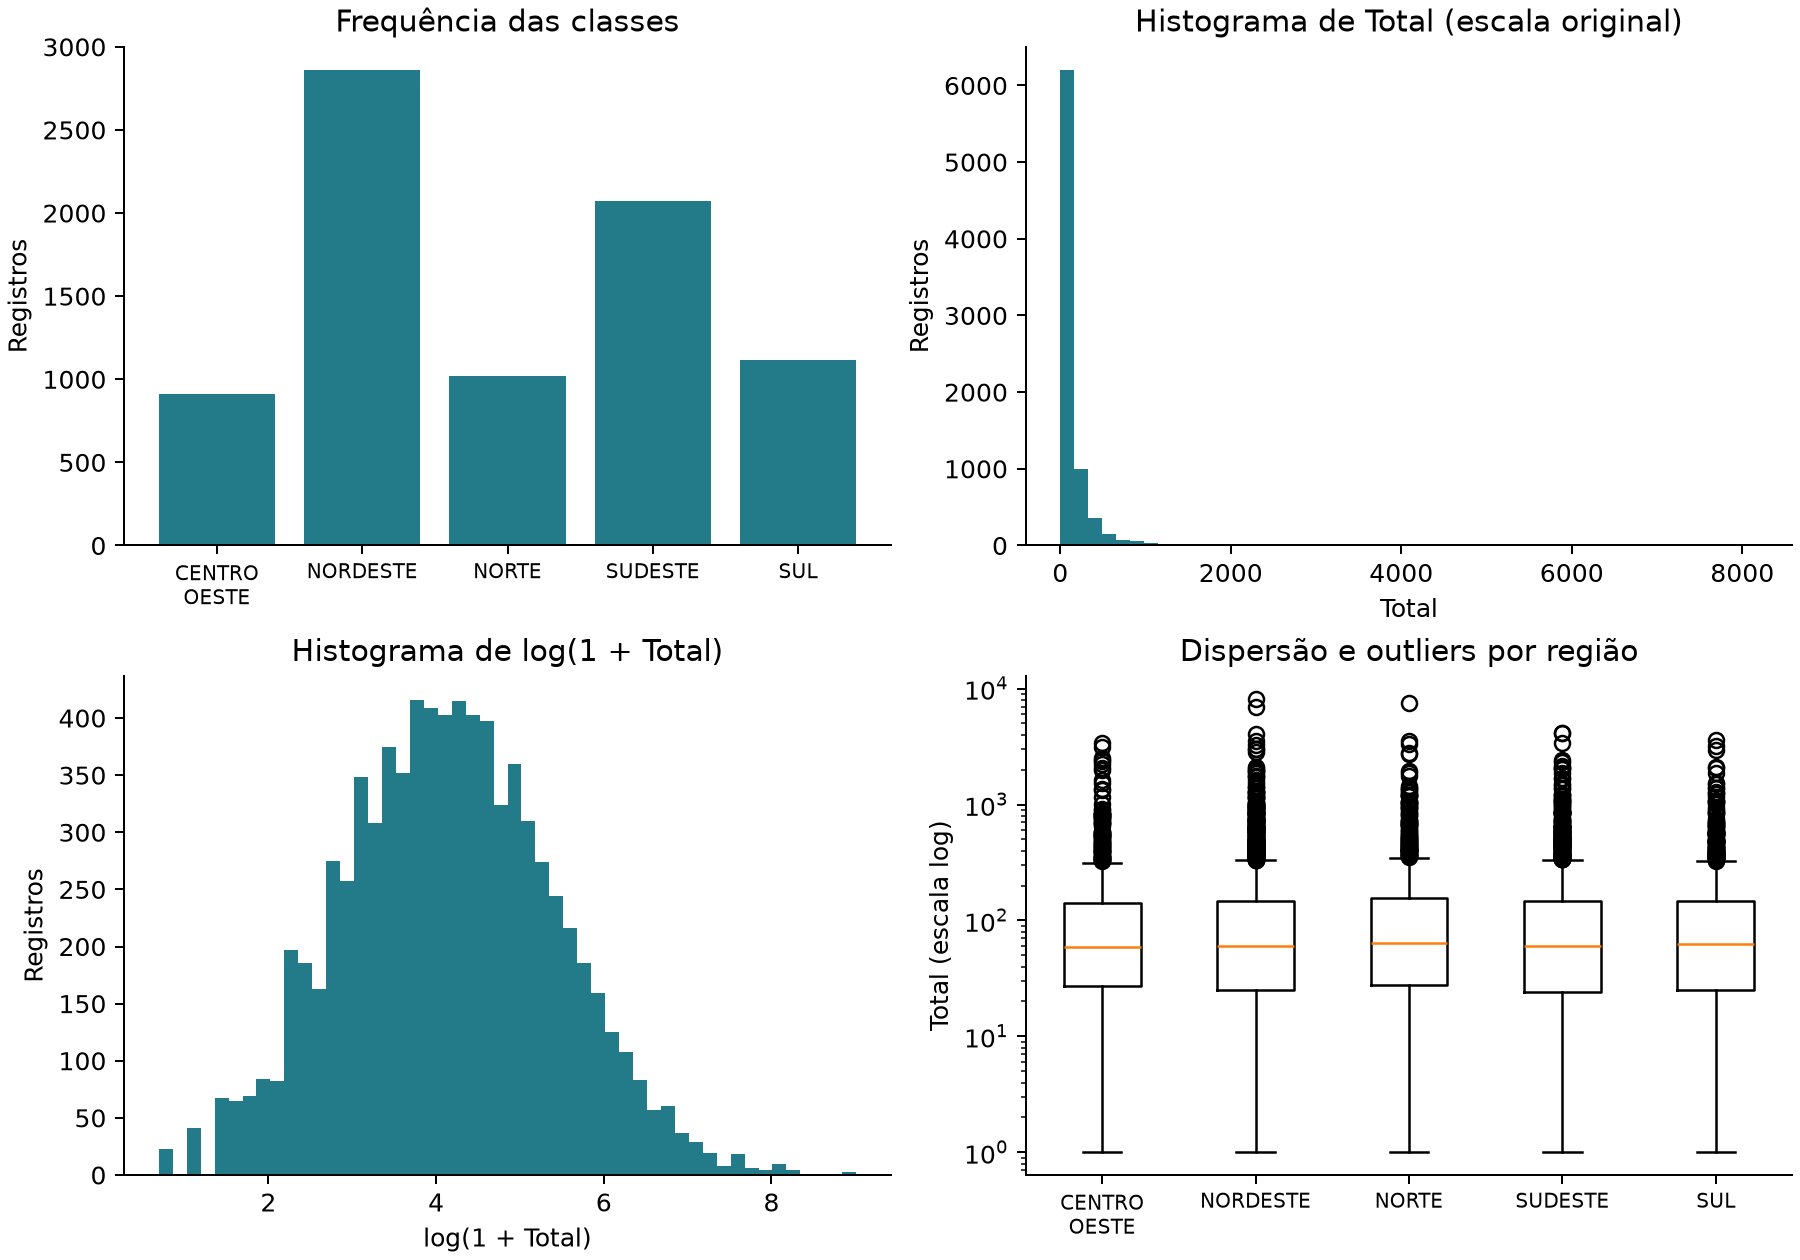

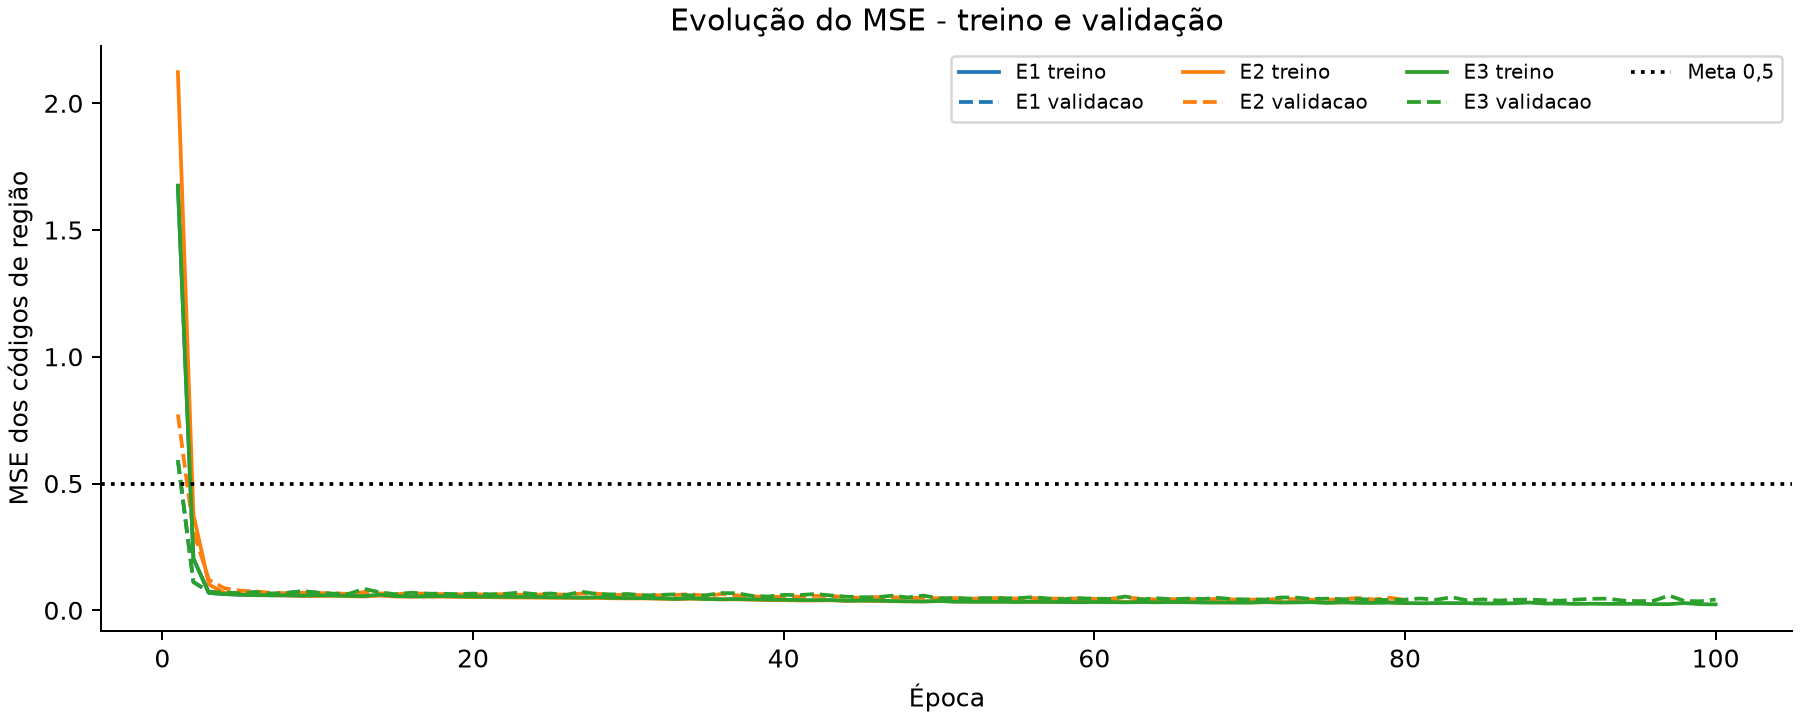

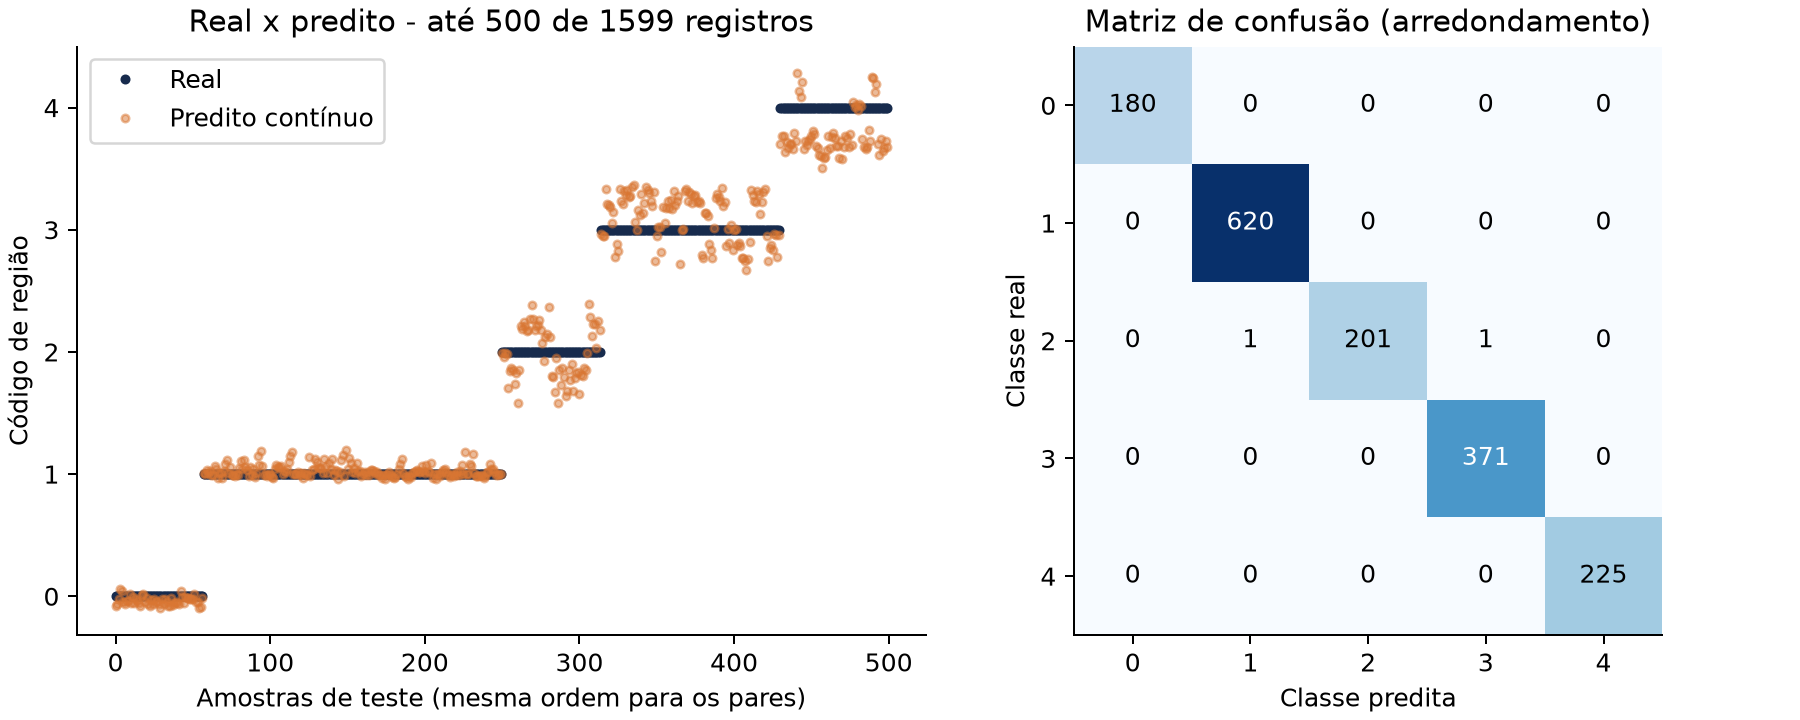

In [3]:
for name in ["histogramas.png", "evolucao_mse.png", "real_predito.png"]:
    display(Image(filename="output/" + name))

## O que este resultado permite concluir

O pipeline funciona em uma base controlada e reproduzível. Os gráficos mostram o desequilíbrio de classes, a cauda de Total e a evolução dos treinamentos efetivamente realizados.

A relação entre UF fictícia e região foi definida no gerador. Assim, o experimento é simples por construção; um mapeamento direto também resolveria a tarefa. Não há evidência de desempenho em dados reais ou de aplicação em saúde.

Para classificação em produção, a saída linear sobre códigos nominais deveria ser revista. Uma saída softmax com métricas por classe seria mais apropriada. O bootstrap atual também não representa a variação entre diferentes inicializações ou divisões.

## Relatório

A pasta `output/` contém o PDF, os CSVs, os dicionários de codificação, a normalização, os históricos e o modelo `.keras`.

In [4]:
display(HTML('<a href="output/Relatorio_RNA_MLP.pdf">Abrir relatório PDF</a>'))